# South Pasopati Coal Project: Reconstructing a Capex-Route Decision (Case Study #14)

**The Feasibility Stress Test, primary lens: Capex Planning.**

Source: Trijayanto, T. & Hakam, D. F. (2025). *Economic Viability and Flexibility of the South Pasopati Coal Project, Indonesia: A Real Options Approach Under Market Volatility and Carbon Pricing.* Journal of Risk and Financial Management, 18(5), 225. DOI 10.3390/jrfm18050225 (open access, CC BY).

## Honesty disclosure
- The open-access HTML text was read through an automated extraction pass, not a manual page-by-page read. Figures and two tables (Table 1 real-option inputs, Table 2 option values) were images and were **not readable**.
- The paper does **not** publish distribution families or parameters for its Monte Carlo inputs, its coal-price regression coefficients, or its cash-flow workbook.
- This notebook is therefore an **illustrative reconstruction**. Everything labelled *paper* comes from the paper's text. Everything labelled *assumption* is mine. The tax rate, straight-line depreciation, flat price, even 4-year output and price volatility below are my assumptions. I calibrate one number per route (the OPEX ratio) so the rebuild hits the paper's deterministic NPV, so matching those three NPVs is by construction and proves nothing.
- Nothing here claims to reproduce the paper's Monte Carlo statistics or real-option values.

In [1]:
import numpy as np, pandas as pd, json, os
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from scipy.stats import spearmanr, norm
plt.rcParams.update({'figure.figsize':(8,4),'axes.grid':True,'grid.alpha':.3})
SEED=20261130
rng=np.random.default_rng(SEED)
OUT={}

# ---- PAPER facts (text of JRFM 18(5) 225) ----
P0=92.82                 # USD/t base coal price (paper)
WACC=0.1142              # discount rate (paper)
REVENUE=158.06           # USD M, project revenue (paper)
CAPEX={'Base (east route)':6.71,'Alt 1 (west route)':8.26,'Alt 2 (east + carbon)':7.29}   # USD M (paper)
PAPER_NPV={'Base (east route)':7.10,'Alt 1 (west route)':4.47,'Alt 2 (east + carbon)':1.32} # USD M (paper)
PAPER_MC={'Base (east route)':(7.19,13.3),'Alt 1 (west route)':(4.49,0.94),'Alt 2 (east + carbon)':(1.24,1.09)}  # mean, SD (paper)
# ---- ASSUMPTIONS (mine) ----
YEARS=4; TAX=0.22
Q=REVENUE/P0             # Mt over life, implied by paper revenue / price
print(f'Implied coal volume = {Q:.3f} Mt (paper: 1.7 Mt reserves)')

Implied coal volume = 1.703 Mt (paper: 1.7 Mt reserves)


## 1. Deterministic rebuild
Revenue = volume x price. OPEX is a fixed USD/t cost equal to `ratio x base price`. Capex is spent at t=0 and depreciated straight-line over 4 years. Tax is 22% of positive EBIT. Flows are end-of-year at WACC 11.42%. The OPEX ratio is the **one calibrated parameter** per route.

In [2]:
def npv(capex, ratio, price=P0, opex_t=None, w=WACC, tax=TAX, q=Q, n=YEARS):
    ot = ratio*P0 if opex_t is None else opex_t
    qa = q/n; dep = capex/n; pv = 0.0
    for t in range(1,n+1):
        ebit = qa*(price-ot)-dep
        cf = qa*(price-ot) - max(ebit,0)*tax
        pv += cf/(1+w)**t
    return pv-capex

ratios={}
rows=[]
for k in CAPEX:
    r=brentq(lambda x: npv(CAPEX[k],x)-PAPER_NPV[k],0.5,1.2); ratios[k]=r
    rows.append([k,CAPEX[k],PAPER_NPV[k],round(r,3),round(npv(CAPEX[k],r),2)])
df=pd.DataFrame(rows,columns=['Route','Capex USD M (paper)','Paper NPV USD M','Calibrated OPEX/revenue (mine)','Rebuild NPV'])
print(df.to_string(index=False))
print('\nPaper says OPEX is 83-89% of revenue across scenarios. Alt 2 needs',round(ratios['Alt 2 (east + carbon)'],3),'to hit its NPV, outside that range.')
OUT['calibrated_opex_ratio']={k:round(v,4) for k,v in ratios.items()}

                Route  Capex USD M (paper)  Paper NPV USD M  Calibrated OPEX/revenue (mine)  Rebuild NPV
    Base (east route)                 6.71             7.10                           0.866         7.10
   Alt 1 (west route)                 8.26             4.47                           0.880         4.47
Alt 2 (east + carbon)                 7.29             1.32                           0.922         1.32

Paper says OPEX is 83-89% of revenue across scenarios. Alt 2 needs 0.922 to hit its NPV, outside that range.


## 2. Does the rebuild agree with the paper's tornado?
The paper reports that a 20% fall in coal price cuts Base NPV by 72%, and a 20% rise in OPEX cuts it by 60%. Apply the same shocks to the rebuild.

In [3]:
c=CAPEX['Base (east route)']; r=ratios['Base (east route)']
base=npv(c,r)
p20=npv(c,r,price=P0*0.8); o20=npv(c,r,opex_t=r*P0*1.2)
print(f'Base NPV                : {base:6.2f}')
print(f'Price -20%  rebuild NPV : {p20:6.2f}  ({(p20/base-1)*100:6.0f}% change)   paper: -72%')
print(f'OPEX +20%   rebuild NPV : {o20:6.2f}  ({(o20/base-1)*100:6.0f}% change)   paper: -60%')
be_p=brentq(lambda p: npv(c,r,price=p),40,P0)
be_r=brentq(lambda x: npv(c,x),0.7,1.2)
print(f'\nBreak-even price  : USD {be_p:.2f}/t  ({(1-be_p/P0)*100:.1f}% below base)')
print(f'Break-even OPEX/revenue : {be_r:.3f}  (vs {r:.3f})')
# how much capex would have to rise to hit NPV=0
be_c=brentq(lambda x: npv(x,r),c,60)
print(f'Break-even capex  : USD {be_c:.1f}M  ({(be_c/c-1)*100:.0f}% above plan)')
OUT['tornado_check']={'base_npv':round(base,2),'price_minus20_npv':round(p20,2),'opex_plus20_npv':round(o20,2),
  'break_even_price':round(be_p,2),'break_even_price_drop_pct':round((1-be_p/P0)*100,1),'break_even_opex_ratio':round(be_r,3),'break_even_capex':round(be_c,1),'break_even_capex_pct_above_plan':round((be_c/c-1)*100)}

Base NPV                :   7.10
Price -20%  rebuild NPV : -14.76  (  -308% change)   paper: -72%
OPEX +20%   rebuild NPV : -11.51  (  -262% change)   paper: -60%

Break-even price  : USD 85.87/t  (7.5% below base)
Break-even OPEX/revenue : 0.941  (vs 0.866)
Break-even capex  : USD 15.3M  (127% above plan)


**Reading:** with the paper's own revenue, volume and OPEX share, this rebuild turns negative after a price fall of roughly 7.5%, and a 20% price fall wipes out the NPV instead of leaving 28% of it. Capex would have to more than double (about +127%) to do the same damage. Either the paper's OPEX partly moves with price (royalty, price-linked contractor rates) in a way the text does not describe, or its tornado is milder than its inputs imply. I cannot tell which from the published text. The capex-vs-price asymmetry is the point either way.

## 3. Monte Carlo on Base: 10,000 trials
**Assumptions (mine, not the paper's):** coal price ~ Normal(92.82, sigma) truncated at USD 20; OPEX ratio ~ Triangular(r-0.03, r, r+0.03); capex ~ Triangular(0.9x, 1.0x, 1.25x) of plan. All independent. The price sigma is the free parameter. The paper does not report it, so I set **13%**, chosen so the Base SD lands near the paper's 13.3. That is a calibration, not a finding.

{'mean': 6.625, 'sd': 13.298, 'p10': -10.779, 'p90': 23.078, 'p_loss': 0.285}
Paper Base MC: mean 7.19, SD 13.3, P10 -9.79, P90 24.16
Loss probability implied by paper mean/SD if roughly normal (my arithmetic): 29.4%


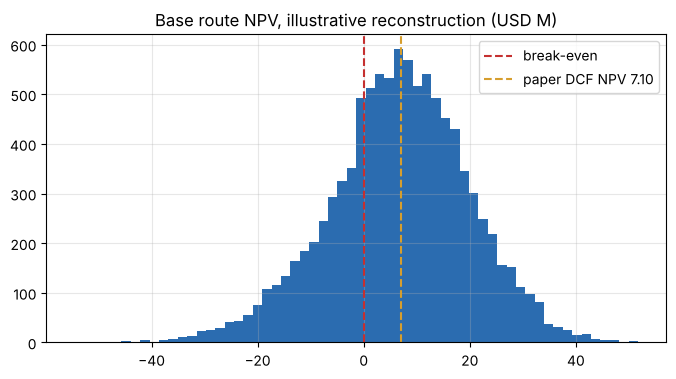

In [4]:
SIG=0.13; N=10000
def simulate(capex, ratio, sig=SIG, n=N, floor=None, seed=SEED):
    rng=np.random.default_rng(seed)
    p=np.clip(rng.normal(P0,sig*P0,n),20,None)
    if floor is not None: p=np.maximum(p,floor)
    ot=rng.triangular(ratio-0.03,ratio,ratio+0.03,n)*P0
    cx=rng.triangular(0.9*capex,capex,1.25*capex,n)
    qa=Q/YEARS; dep=cx/YEARS; pv=np.zeros(n)
    for t in range(1,YEARS+1):
        ebit=qa*(p-ot)-dep
        pv+=(qa*(p-ot)-np.maximum(ebit,0)*TAX)/(1+WACC)**t
    return pv-cx, p, ot, cx

v,p,ot,cx=simulate(c,r)
stats={'mean':v.mean(),'sd':v.std(ddof=1),'p10':np.percentile(v,10),'p90':np.percentile(v,90),'p_loss':(v<0).mean()}
print({k:round(float(x),3) for k,x in stats.items()})
print('Paper Base MC: mean 7.19, SD 13.3, P10 -9.79, P90 24.16')
pm,ps=PAPER_MC['Base (east route)']
print(f'Loss probability implied by paper mean/SD if roughly normal (my arithmetic): {norm.cdf(-pm/ps)*100:.1f}%')
plt.hist(v,bins=60,color='#2b6cb0'); plt.axvline(0,color='#c53030',ls='--',label='break-even'); plt.axvline(PAPER_NPV['Base (east route)'],color='#d69e2e',ls='--',label='paper DCF NPV 7.10')
plt.title('Base route NPV, illustrative reconstruction (USD M)'); plt.legend(); plt.show()
OUT['base_mc']={k:round(float(x),3) for k,x in stats.items()}; OUT['base_mc']['price_sigma']=SIG
OUT['paper_implied_p_loss_normal_approx']=round(float(norm.cdf(-pm/ps)),3)

## 4. The route comparison: same price exposure, so why 14x less dispersion?
The paper reports Monte Carlo SDs of 13.3 (Base), 0.94 (Alt 1) and 1.09 (Alt 2). Run all three routes through the **same** price and cost uncertainty (same random seed, so the comparison is like for like).

In [5]:
rows=[]; sims={}
for k in CAPEX:
    vv,_,_,_=simulate(CAPEX[k],ratios[k]); sims[k]=vv
    rows.append([k,PAPER_MC[k][0],PAPER_MC[k][1],round(vv.mean(),2),round(vv.std(ddof=1),2),round((vv<0).mean()*100,1)])
rt=pd.DataFrame(rows,columns=['Route','Paper MC mean','Paper MC SD','Rebuild mean','Rebuild SD','Rebuild P(NPV<0) %'])
print(rt.to_string(index=False))
OUT['route_comparison']=rt.to_dict(orient='records')

                Route  Paper MC mean  Paper MC SD  Rebuild mean  Rebuild SD  Rebuild P(NPV<0) %
    Base (east route)           7.19        13.30          6.63       13.30                28.6
   Alt 1 (west route)           4.49         0.94          3.75       13.52                36.4
Alt 2 (east + carbon)           1.24         1.09          0.31       13.87                45.8


**Reading:** once every route faces the same coal price, dispersion is nearly identical, because 80-90% of every dollar is price and OPEX, not route-specific capex. The paper's Alt 1 and Alt 2 SDs near 1 would need those routes to face almost none of the price risk that Base carries. The paper gives no reason. I flag it rather than explain it.

## 5. What drives Base NPV in the rebuild? (Spearman rank correlation)

Coal price   +0.99
OPEX ratio   -0.08
Capex        -0.03


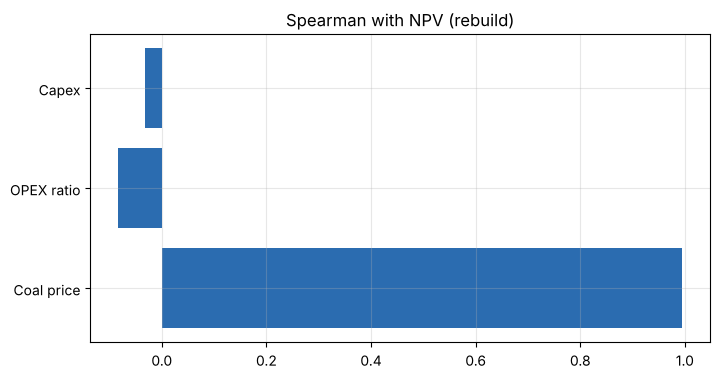

In [6]:
sp={'Coal price':spearmanr(p,v)[0],'OPEX ratio':spearmanr(ot,v)[0],'Capex':spearmanr(cx,v)[0]}
for k,x in sp.items(): print(f'{k:12s} {x:+.2f}')
plt.barh(list(sp.keys()),list(sp.values()),color='#2b6cb0'); plt.title('Spearman with NPV (rebuild)'); plt.show()
OUT['spearman']={k:round(float(x),3) for k,x in sp.items()}

## 6. What would a board do differently? A price-floor illustration (mine, not the paper's)
The paper's real-option result says execute: underlying PV USD 14.55M against USD 6.71M investment, option value USD 0.95M, ENPV 8.05M, with a 38% chance of abandoning. It reports no realised outcome. A board reading that alongside a roughly 30% loss probability can ask what an offtake price floor does. The floor below is a **free** floor, with no premium or counterparty cost, so it is an upper bound on the benefit.

In [7]:
rows=[]
for f in [None,0.85,0.90,0.95,1.00]:
    vv,_,_,_=simulate(c,r,floor=None if f is None else f*P0)
    rows.append(['no floor' if f is None else f'floor at {int(f*100)}% of base price',round(vv.mean(),2),round(vv.std(ddof=1),2),round((vv<0).mean()*100,1)])
fl=pd.DataFrame(rows,columns=['Case','Mean NPV','SD','P(NPV<0) %']); print(fl.to_string(index=False))
print(f'\nBreak-even price is {be_p/P0*100:.1f}% of base, so a floor below that level cannot remove the loss branch.')
OUT['price_floor']=fl.to_dict(orient='records')

                       Case  Mean NPV    SD  P(NPV<0) %
                   no floor      6.63 13.30        28.6
 floor at 85% of base price      7.56 11.59        28.6
 floor at 90% of base price      8.53 10.37        28.4
 floor at 95% of base price      9.93  8.99         1.6
floor at 100% of base price     11.90  7.47         0.0

Break-even price is 92.5% of base, so a floor below that level cannot remove the loss branch.


## 7. Export

In [8]:
os.makedirs('data',exist_ok=True)
OUT['meta']={'seed':SEED,'trials':N,'tax':TAX,'years':YEARS,'volume_mt':round(Q,3),'note':'Illustrative reconstruction; opex ratio calibrated to paper NPVs; price sigma 13% is an assumption.'}
with open('data/notebook_reconstruction_output.json','w') as f: json.dump(OUT,f,indent=2)
print(json.dumps(OUT,indent=1)[:1500])

{
 "calibrated_opex_ratio": {
  "Base (east route)": 0.8663,
  "Alt 1 (west route)": 0.8804,
  "Alt 2 (east + carbon)": 0.9222
 },
 "tornado_check": {
  "base_npv": 7.1,
  "price_minus20_npv": -14.76,
  "opex_plus20_npv": -11.51,
  "break_even_price": 85.87,
  "break_even_price_drop_pct": 7.5,
  "break_even_opex_ratio": 0.941,
  "break_even_capex": 15.3,
  "break_even_capex_pct_above_plan": 127
 },
 "base_mc": {
  "mean": 6.625,
  "sd": 13.298,
  "p10": -10.779,
  "p90": 23.078,
  "p_loss": 0.285,
  "price_sigma": 0.13
 },
 "paper_implied_p_loss_normal_approx": 0.294,
 "route_comparison": [
  {
   "Route": "Base (east route)",
   "Paper MC mean": 7.19,
   "Paper MC SD": 13.3,
   "Rebuild mean": 6.63,
   "Rebuild SD": 13.3,
   "Rebuild P(NPV<0) %": 28.6
  },
  {
   "Route": "Alt 1 (west route)",
   "Paper MC mean": 4.49,
   "Paper MC SD": 0.94,
   "Rebuild mean": 3.75,
   "Rebuild SD": 13.52,
   "Rebuild P(NPV<0) %": 36.4
  },
  {
   "Route": "Alt 2 (east + carbon)",
   "Paper MC mean":